<a href="https://colab.research.google.com/github/MichalSlowakiewicz/Large-Scale-Machine-Learning/blob/master/LAB_6_mslowakiewicz.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab - Calculating Model FLOPs, Memory, Memory Throughput, MFU

In this lab, you will practice calculating and estimating the performance of LLMs in various scenarios. We will focus on the original LLaMA 7B model.

Please refer to lectures about [Transformers](https://docs.google.com/presentation/d/1AmfsaJNq5A5HeNxSg6oXrc1quBk5yubEKCAJzBGZa0Q/edit?usp=sharing) and [GPUs](https://docs.google.com/presentation/d/1iHmOeFeSBbeN9VWB_ELxNxdJWEN10icnx_mI0MgXEgo/edit?usp=sharing).

# GPU Specification

Here you can find the technical specifications for the A100 GPU: https://www.nvidia.com/content/dam/en-zz/Solutions/Data-Center/a100/pdf/nvidia-a100-datasheet-us-nvidia-1758950-r4-web.pdf

Technical specifications for the H100: https://www.nvidia.com/en-us/data-center/h100/

Note that we usually do not use "sparsity", so when looking up FLOPS, use the (lower) number of FLOPS without sparsity. For example, for the A100 and BFLOAT16, we use 312 TFLOPS, not 624 TFLOPS with sparsity. If the number without sparsity is not provided (as in the H100 spec), it is probably just half of the sparsity number (so half of the claimed 1,979 TFLOPS is approximately 989 TFLOPS). Unfortunately, due to marketing departments, tech specs are usually provided with the highest possible number, not the most useful one.

# Assumptions

In the entire notebook, let's assume we use 16-bit numbers (bfloat16) everywhere. Therefore, 1 float = 2 bytes.

In [20]:
# TODO
a100_flops = 312 * 1e12   # for 16bit
a100_mem_bytes = 80 * 1e9
a100_mem_floats = a100_mem_bytes / 2   # assuming 16bit
a100_mem_bandwidth_bytes = 1935 * 1e9
a100_mem_bandwidth_floats = a100_mem_bandwidth_bytes / 2

# Number of Parameters and Activations
Let's take a config of the original LLaMA, e.g., from [here](https://huggingface.co/huggyllama/llama-7b/blob/main/config.json).

OPTIONAL: You can also take a config from Llama 3 8B, e.g., from [here](https://huggingface.co/unsloth/llama-3-8b/blob/main/config.json) or the official source on [this HuggingFace page](https://huggingface.co/meta-llama/Meta-Llama-3-8B/blob/main/config.json) (inaccessible without logging in and agreeing to the model license). However, note that Llama 3 uses grouped query attention—essentially, it has four times smaller key-value linear projections and four times smaller key-value cache (see [this blogpost](https://adithyask.medium.com/from-7b-to-8b-parameters-understanding-weight-matrix-changes-in-llama-transformer-models-31ea7ed5fd88) for step-by-step calculations).

Let's start with an easy one: how many parameters do we have in this model? Will it fit on a single GPU?

In [21]:
# TODO
# Original LLaMA
n_layers = 32
vocab_size = 32000
d_model = 4096
# d_ff is also called an intermediate size
d_ff = 11008
n_heads = 32
d_heads = d_model // n_heads

# Llama 3 8B
# n_layers = <same>
# vocab_size = 128256  # Llama 2 had 32000
# d_model = <same>
# d_ff = 14336  # Llama 2 had 11008
# n_heads = <same>
# d_heads = d_model // n_heads

In [22]:
# TODO
# Tip: you don't need to count biases, LayerNorms, etc.

emb_params = vocab_size * d_model
unemb_params = vocab_size * d_model
# The field below is provided on purpose
ff_layer_params = n_layers * ((d_model * d_ff) * 3) # 2 for a plain MLP (ReLU, GeLU), 3 for a gated one (SwiGLU, as in LLaMA)
att_layer_params = n_layers * 4 * d_model * n_heads * d_heads
total_params = emb_params + unemb_params + ff_layer_params + att_layer_params
print(f"{total_params=}")

total_params=6738149376


During inference, the majority of non-model memory usage comes from the KV cache. What's the size of the KV cache per token in this model?

In [23]:
# TODO
kv_cache_per_token = 2 * n_layers * n_heads * d_heads
print(f"{kv_cache_per_token=}")

kv_cache_per_token=262144


During training, we must either remember all the activations of the model (standard training without activation checkpointing) or the activation after each Feed-Forward and Attention layer (training with activation checkpointing).

What is the total size of all activations per token, assuming no checkpointing?

What is the total size of all activations per token, assuming checkpointing after each Feed-Forward and each Attention?

You can assume chunking of the loss layer (do not count outputs of the Unembedding). This technique will be described in a future lecture.

In [24]:
# TODO
# It's okay to get this number approximately right, not exactly; don't focus on constants.
activations_per_token_no_checkpoints = n_layers * (5 * d_model + 3 * d_ff)
activations_per_token_with_checkpoints = n_layers * d_model

print(f"{activations_per_token_no_checkpoints=}")
print(f"{activations_per_token_with_checkpoints=}")

activations_per_token_no_checkpoints=1712128
activations_per_token_with_checkpoints=131072


# Calculating Maximum Number of Processed Tokens

Assuming an 80GB A100, what is the maximum possible context length for inference? What about for training, with or without activation checkpointing?

What if we assume 40GB instead of 80GB?
Can we even fit the model for training (with gradients and Adam state) in 40GB?

Remember to subtract model-dependent memory (weights, gradients, Adam state...) from available memory.

In [25]:
# TODO
# inference calculations
inference_tokens_80gb = (a100_mem_floats - total_params) / kv_cache_per_token
inference_tokens_40gb = (a100_mem_floats / 2 - total_params) / kv_cache_per_token

print(f"{inference_tokens_80gb=}")
print(f"{inference_tokens_40gb=}")

inference_tokens_80gb=126883.890625
inference_tokens_40gb=50589.9453125


In [26]:
# TODO
# training calculations
training_tokens_no_checkpoints_80gb = (a100_mem_floats - 4 * total_params) / activations_per_token_no_checkpoints
training_tokens_with_checkpoints_80gb = (a100_mem_floats - 4 * total_params) / activations_per_token_with_checkpoints

print(f"{training_tokens_no_checkpoints_80gb=}")
print(f"{training_tokens_with_checkpoints_80gb=}")

training_tokens_no_checkpoints_40gb = (a100_mem_floats / 2 - 4 * total_params) / activations_per_token_no_checkpoints
training_tokens_with_checkpoints_40gb = (a100_mem_floats / 2 - 4 * total_params) / activations_per_token_with_checkpoints

print(f"{training_tokens_no_checkpoints_40gb=}")
print(f"{training_tokens_with_checkpoints_40gb=}")

training_tokens_no_checkpoints_80gb=7620.576555023923
training_tokens_with_checkpoints_80gb=99543.78125
training_tokens_no_checkpoints_40gb=-4060.793062200957
training_tokens_with_checkpoints_40gb=-53044.109375


# FLOPs to Train

We will assume 100% MFU is possible if not bottlenecked by memory throughput (this is essentially impossible to achieve; usually, we can assume around 50%, depending on the model and load).

We can assume the Attention mechanism doesn't take any computation (e.g., we have short sequences).

For costs, we can assume a single hour of A100 is worth 2 USD.

In [27]:
# hint: if we don't care about memory transfer, batch size doesn't matter
inference_flops_per_token = 2 * total_params
inference_time_per_token = inference_flops_per_token / a100_flops
print(f"{inference_time_per_token=}")

training_no_checkpoints_flops_per_token = 6 * total_params
training_no_checkpoints_time_per_token = training_no_checkpoints_flops_per_token / a100_flops
print(f"{training_no_checkpoints_time_per_token=}")

training_with_checkpoints_flops_per_token = 8 * total_params
training_with_checkpoints_time_per_token = training_with_checkpoints_flops_per_token / a100_flops
print(f"{training_with_checkpoints_time_per_token=}")

inference_time_per_token=4.319326523076923e-05
training_no_checkpoints_time_per_token=0.0001295797956923077
training_with_checkpoints_time_per_token=0.00017277306092307692


Assume you want to evaluate LLaMA on a dataset of 100M tokens. How much time do you need? What is the renting cost?

(For now, let's assume 100% MFU and no issues with memory throughput.)

In [28]:
# TODO
gpu_hours = 1e8 * inference_time_per_token / 3600
cost_USD = gpu_hours * 2
print(f"{gpu_hours=}")
print(f"{cost_USD=}")

gpu_hours=1.199812923076923
cost_USD=2.399625846153846


Assume you want to fine-tune LLaMA on a private dataset of 3B tokens. How much will it cost?

(For now, let's assume 100% MFU and no problems with memory throughput.)

In [29]:
# TODO
gpu_hours = 3e9 * training_with_checkpoints_time_per_token / 3600 # assuming checkpointing
cost_USD = gpu_hours * 2
print(f"{gpu_hours=}")
print(f"{cost_USD=}")

gpu_hours=143.97755076923076
cost_USD=287.9551015384615


LLaMA 7B was trained on approximately 1 trillion tokens (the larger 33B and 65B models on 1.4 trillion). How many GPU hours would that be, assuming 100% FLOPS utilization?

In [30]:
# TODO
gpu_hours = 1e12 * training_with_checkpoints_time_per_token / 3600 # assuming checkpointing
cost_USD = gpu_hours * 2
print(f"{gpu_hours=}")
print(f"{cost_USD=}")

gpu_hours=47992.516923076924
cost_USD=95985.03384615385


# Memory Throughput for Training

Memory throughput makes larger batch sizes more critical. During each evaluation or training step, we generally need to read and write all model weights (and gradients, and Adam state), and read and write all activations.

Because the number of reads/writes for model-type tensors is constant (independent of batch size), and the number of reads/writes for activation-type tensors grows linearly with batch size, larger batch sizes will generally be better.

How long does it take to run a training batch of 1 or 32 or 1024 or 32\*1024 or 1024\*1024 tokens? When are we bottlenecked by FLOPS, and when are we bottlenecked by memory throughput?

In [31]:
# memory: doesn't matter how big is the batch size!
# note that each activation must be both saved and loaded
def get_transferring_time_per_token(batch_size, params, activations):
  transfers_per_batch = 8 * params + 2 * batch_size * activations
  transfers_time_per_batch = transfers_per_batch / a100_mem_bandwidth_floats
  transfers_time_per_token = transfers_time_per_batch / batch_size
  return transfers_time_per_token

for batch_size in [1, 32, 1024, 32*1024, 1024*1024]:
  transferring_time_per_token = get_transferring_time_per_token(batch_size, total_params, activations_per_token_no_checkpoints)
  print(f"{batch_size=}")
  print(f"{transferring_time_per_token=}")

batch_size=1
transferring_time_per_token=0.055719503115245476
batch_size=32
transferring_time_per_token=0.0017446631524547804
batch_size=1024
transferring_time_per_token=5.794940361757106e-05
batch_size=32768
transferring_time_per_token=5.239598966408269e-06
batch_size=1048576
transferring_time_per_token=3.5924175710594316e-06


# Calculating Max MFU

If we are bottlenecked by memory loads (i.e., memory transfer requires more time than FLOPS), the MFU must be below 100%.

Plot the possible MFU against the training batch size. You can assume that memory transfer happens in parallel with computation (this isn't always the case, but it's alright to assume here).

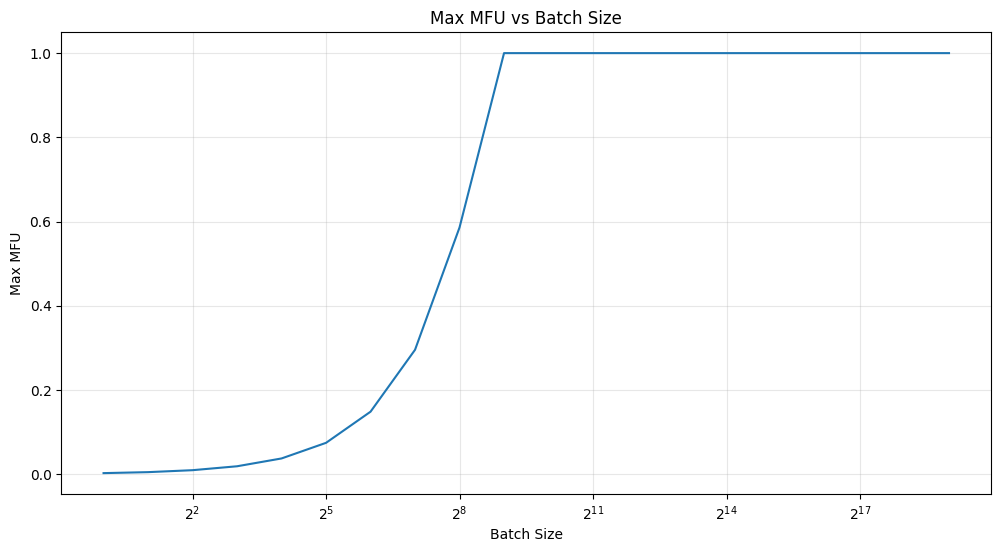

In [32]:
# TODO by students
def mfu_calc(batch_size, params, activations):
  computation_time_per_token = 6 * params / a100_flops
  transferring_time_per_token = get_transferring_time_per_token(batch_size, params, activations)

  mfu = computation_time_per_token / max(computation_time_per_token, transferring_time_per_token)
  return mfu

batch_sizes = [2**x for x in range(20)]
mfu_values = [mfu_calc(batch_size, total_params, activations_per_token_no_checkpoints) for batch_size in batch_sizes]

# TODO: plot
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(batch_sizes, mfu_values)
plt.xscale('log', base=2)
plt.xlabel('Batch Size')
plt.ylabel('Max MFU')
plt.title('Max MFU vs Batch Size')
plt.grid(True, alpha=0.3)
plt.show()

# Optional Exercises

You can calculate the answers to the questions below, or try to estimate.

1. During autoregressive inference, we process only the last token while keeping the KV-cache for all previous tokens in the sequence. This KV-cache has to be read in each step of the inference. What is the context length beyond which we will always be bottlenecked by memory throughput, no matter the total batch size?

2. Assuming a constant depth-to-width ratio, what is the "minimal model" that is reasonable to train on an A100? That is, the smallest model not bottlenecked by memory (with any batch size); you can plot MFU and check at what point there is a drop-off.
Does it depend on the model width, or depth, or both?

3. Assuming a constant depth-to-width ratio, what is the minimal batch size for a given model to achieve 100% MFU (in theory)?

4. What is the maximum model size one can train using a single A100 GPU? What if we have a node of 8xA100? How does it change with activation checkpointing?